# Лабораторна робота №10
**«Теорія розпізнавання образів та класифікації в системах ШІ»**

* **Тема:** Ансамблеві методи класифікації. Бустинг (AdaBoost, Gradient Boosting)
* **Команда:** банк
* **Склад команди:** Сотниченко Артем Валентинович, Вірченко Богдан, Тринько Микита
* **Група:** КН23002б
* **Тема проєкту:** AI-система прогнозування відтоку клієнтів банку, банківський скоринг

**Мета роботи:** набути практичних навичок побудови AdaBoost і градієнтного бустингу, дослідити вплив темпу навчання й кількості ітерацій на перенавчання, порівняти якість і стійкість до шуму з випадковим лісом

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")

# Завантаження даних
TARGET = "Exited"
TRAIN_PATH = "Churn_train_prepared.csv"
TEST_PATH = "Churn_test_prepared.csv"
RANDOM_STATE = 42

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]

print(f"Дані завантажено. Тренувальна вибірка: {X_train.shape}, Тестова: {X_test.shape}")

Дані завантажено. Тренувальна вибірка: (8000, 9), Тестова: (2000, 9)


## Завдання 1. Побудова AdaBoost та порівняння з випадковим лісом
Побудуємо базовий AdaBoostClassifier. Для порівняння навчимо випадковий ліс із 500 деревами на тому самому поділі даних. Accuracy показує частку правильних прогнозів для всіх клієнтів, а F1 для класу 1 враховує, наскільки точно й повно модель знаходить клієнтів, які залишили банк

In [2]:
# Базовий AdaBoost і випадковий ліс із лаб. №9
ada = AdaBoostClassifier(random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, n_jobs=-1)
ada.fit(X_train, y_train)
rf.fit(X_train, y_train)

def model_scores(model):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    return {
        "Train accuracy": accuracy_score(y_train, train_pred),
        "Test accuracy": accuracy_score(y_test, test_pred),
        "Train F1": f1_score(y_train, train_pred, zero_division=0),
        "Test F1": f1_score(y_test, test_pred, zero_division=0)
    }

base_comp = pd.DataFrame({
    "AdaBoost": model_scores(ada),
    "Random Forest": model_scores(rf)
}).T
display(base_comp.round(4))
print("Метрики базового AdaBoost за класами")
print(classification_report(y_test, ada.predict(X_test), digits=4, zero_division=0))

,Train accuracy,Test accuracy,Train F1,Test F1
AdaBoost,0.8508,0.852,0.5314,0.5502
Random Forest,1.0000,0.855,1.0000,0.5593


Метрики базового AdaBoost за класами
              precision    recall  f1-score   support

           0     0.8708    0.9561    0.9114      1593
           1     0.7211    0.4447    0.5502       407

    accuracy                         0.8520      2000
   macro avg     0.7959    0.7004    0.7308      2000
weighted avg     0.8403    0.8520    0.8379      2000



## Завдання 2. Побудова Gradient Boosting та дослідження гіперпараметрів
Перевіримо, як змінюється F1 при різних значеннях learning_rate та n_estimators. Для вибору темпу навчання виділимо 20% тренувальних даних на валідацію. Порівняємо темпи при однаковій кількості дерев (200) за validation accuracy. На початковому тестовому наборі побудуємо таблицю F1 та графік точності

In [3]:
# Базовий Gradient Boosting
gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb.fit(X_train, y_train)
display(pd.DataFrame([model_scores(gb)], index=["Gradient Boosting"]).round(4))

learning_rates = [0.01, 0.1, 0.5, 1.0]
n_estimators_list = [10, 50, 100, 200]
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)

# Вибір темпу навчання при 200 деревах
val_scores = {}
for lr in learning_rates:
    gb_val = GradientBoostingClassifier(learning_rate=lr, n_estimators=200, random_state=RANDOM_STATE)
    gb_val.fit(X_fit, y_fit)
    val_scores[lr] = gb_val.score(X_val, y_val)

val_accuracy = pd.Series(val_scores, name="Validation accuracy").rename_axis("Learning Rate")
best_lr = val_accuracy.idxmax()
display(val_accuracy.to_frame().round(4))
print(f"Обраний learning_rate при 200 деревах: {best_lr:g}")

,Train accuracy,Test accuracy,Train F1,Test F1
Gradient Boosting,0.8698,0.8695,0.5998,0.6015


,Validation accuracy
Learning Rate,
0.01,0.8450
0.10,0.8575
0.50,0.8488
1.00,0.8269


Обраний learning_rate при 200 деревах: 0.1


Estimators,10,50,100,200
Learning Rate,,,,
0.01,0.0000,0.0049,0.3615,0.5122
0.10,0.3615,0.5764,0.6015,0.5979
0.50,0.5705,0.5893,0.5626,0.5569
1.00,0.5769,0.5657,0.5556,0.5248


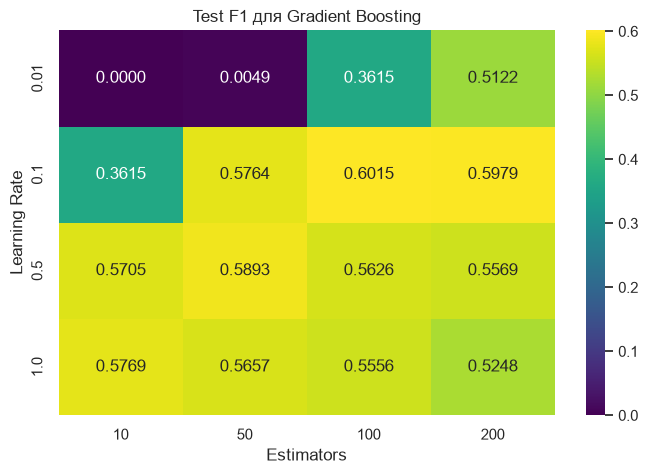

In [4]:
# Дослідження параметрів Gradient Boosting на початковому поділі
gb_results = []
for lr in learning_rates:
    gb_grid = GradientBoostingClassifier(learning_rate=lr, n_estimators=200, random_state=RANDOM_STATE)
    gb_grid.fit(X_train, y_train)
    # staged_predict дає прогнози після кожного доданого дерева
    stages = zip(gb_grid.staged_predict(X_train), gb_grid.staged_predict(X_test))
    for n, (train_pred, test_pred) in enumerate(stages, start=1):
        if n in n_estimators_list:
            gb_results.append({
                "Learning Rate": lr, "Estimators": n,
                "Train F1": f1_score(y_train, train_pred, zero_division=0),
                "Test F1": f1_score(y_test, test_pred, zero_division=0)
            })

gb_df = pd.DataFrame(gb_results)
pivot_test = gb_df.pivot(index="Learning Rate", columns="Estimators", values="Test F1")
display(pivot_test.round(4))
plt.figure(figsize=(8, 5))
sns.heatmap(pivot_test, annot=True, fmt=".4f", cmap="viridis")
plt.title("Test F1 для Gradient Boosting")
plt.show()

## Завдання 3. Дослідження ризику перенавчання (бустинг проти лісу)
Для обраного темпу навчання простежимо за train і test accuracy після кожної ітерації. Позначимо максимум test accuracy та перший спад після нього. Окремо порівняємо агресивний градієнтний бустинг із випадковим лісом при 500 деревах

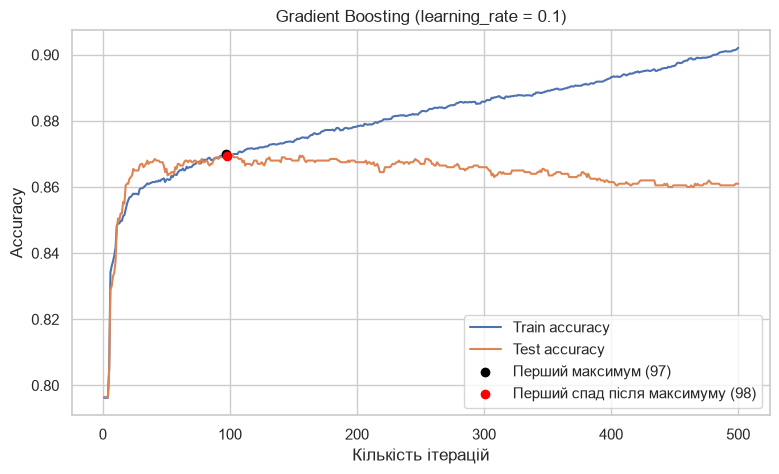

Максимальна test accuracy 0.8700 вперше досягнута на ітерації 97.
Перший спад після максимуму зафіксовано на ітерації 98 (test accuracy 0.8695).


In [5]:
gb_curve = GradientBoostingClassifier(learning_rate=best_lr, n_estimators=500, random_state=RANDOM_STATE)
gb_curve.fit(X_train, y_train)

curve = pd.DataFrame({
    "Train accuracy": [accuracy_score(y_train, pred) for pred in gb_curve.staged_predict(X_train)],
    "Test accuracy": [accuracy_score(y_test, pred) for pred in gb_curve.staged_predict(X_test)]
}, index=pd.RangeIndex(1, 501, name="Кількість ітерацій"))

peak_n = curve["Test accuracy"].idxmax()
peak_acc = curve.loc[peak_n, "Test accuracy"]
after_peak = curve.loc[peak_n + 1:]
below_peak = after_peak[after_peak["Test accuracy"] < peak_acc]

ax = curve.plot(figsize=(9, 5))
ax.scatter(peak_n, peak_acc, color="black", label=f"Перший максимум ({peak_n})", zorder=3)
if below_peak.empty:
    drop_answer = "До кінця дослідженого діапазону спаду після максимуму не зафіксовано."
else:
    drop_n = below_peak.index[0]
    drop_acc = curve.loc[drop_n, "Test accuracy"]
    ax.scatter(drop_n, drop_acc, color="red", label=f"Перший спад після максимуму ({drop_n})", zorder=3)
    drop_answer = f"Перший спад після максимуму зафіксовано на ітерації {drop_n} (test accuracy {drop_acc:.4f})."
ax.set(title=f"Gradient Boosting (learning_rate = {best_lr:g})", ylabel="Accuracy")
ax.legend()
plt.show()
print(f"Максимальна test accuracy {peak_acc:.4f} вперше досягнута на ітерації {peak_n}.")
print(drop_answer)

In [6]:
# Агресивний градієнтний бустинг (високий learning_rate і багато дерев)
gb_aggressive = GradientBoostingClassifier(learning_rate=0.5, n_estimators=500, random_state=RANDOM_STATE)
gb_aggressive.fit(X_train, y_train)

overfit_comp = pd.DataFrame({
    "Random Forest": base_comp.loc["Random Forest"].to_dict(),
    "Gradient Boosting": model_scores(gb_aggressive)
}).T
overfit_comp["Розрив F1"] = overfit_comp["Train F1"] - overfit_comp["Test F1"]
display(overfit_comp.round(4))

,Train accuracy,Test accuracy,Train F1,Test F1,Розрив F1
Random Forest,1.0000,0.8550,1.0000,0.5593,0.4407
Gradient Boosting,0.9875,0.8335,0.9686,0.5316,0.4370


## Завдання 4. Чутливість до шуму в даних
Створимо зашумлену тренувальну вибірку. Інвертуємо 8% випадкових міток і перевіримо стійкість трьох моделей на чистій тестовій вибірці. Для кожної моделі залишимо однакові параметри до і після додавання шуму

Інвертовано міток: 640 з 8000


,Чисті дані accuracy,Дані з шумом accuracy,Падіння accuracy (в.п.),Чисті дані F1,Дані з шумом F1,Падіння F1 (%)
Модель,,,,,,
Random Forest,0.8545,0.8500,0.45,0.5598,0.5575,0.3994
AdaBoost,0.8525,0.8560,-0.35,0.5524,0.5429,1.7190
Gradient Boosting,0.8695,0.8655,0.40,0.6015,0.5750,4.4033


Від’ємне падіння означає, що метрика після додавання шуму зросла.


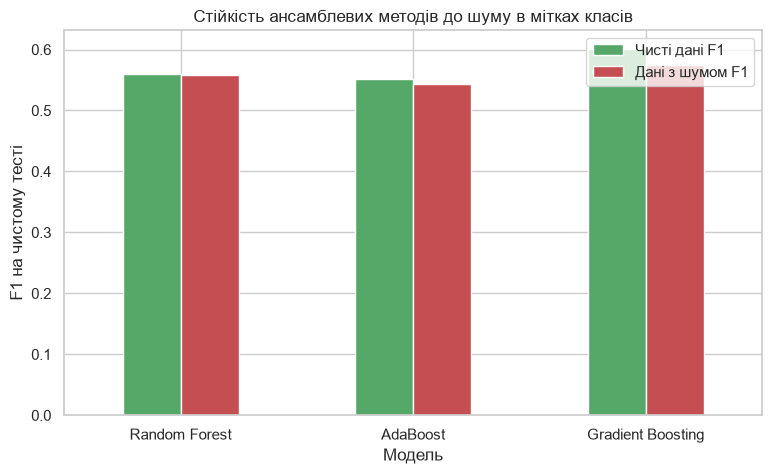

In [7]:
# Створення шуму в тренувальних даних
rng = np.random.RandomState(RANDOM_STATE)
noise_fraction = 0.08
n_noise = int(len(y_train) * noise_fraction)
noise_indices = rng.choice(y_train.index, size=n_noise, replace=False)

y_train_noisy = y_train.copy()
y_train_noisy.loc[noise_indices] = 1 - y_train_noisy.loc[noise_indices]
print(f"Інвертовано міток: {n_noise} з {len(y_train)}")

# Для цього експерименту беремо по 100 дерев
models_noise = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

noise_results = []
for name, model in models_noise.items():
    model.fit(X_train, y_train)
    clean_pred = model.predict(X_test)
    model.fit(X_train, y_train_noisy)
    noisy_pred = model.predict(X_test)

    clean_acc = accuracy_score(y_test, clean_pred)
    noisy_acc = accuracy_score(y_test, noisy_pred)
    clean_f1 = f1_score(y_test, clean_pred, zero_division=0)
    noisy_f1 = f1_score(y_test, noisy_pred, zero_division=0)
    noise_results.append({
        "Модель": name,
        "Чисті дані accuracy": clean_acc, "Дані з шумом accuracy": noisy_acc,
        "Падіння accuracy (в.п.)": 100 * (clean_acc - noisy_acc),
        "Чисті дані F1": clean_f1, "Дані з шумом F1": noisy_f1,
        "Падіння F1 (%)": 100 * (clean_f1 - noisy_f1) / clean_f1 if clean_f1 else np.nan
    })

noise_df = pd.DataFrame(noise_results).set_index("Модель")
display(noise_df.round(4))
print("Від’ємне падіння означає, що метрика після додавання шуму зросла.")

noise_df[["Чисті дані F1", "Дані з шумом F1"]].plot(
    kind="bar", figsize=(9, 5), color=["#55A868", "#C44E52"]
)
plt.title("Стійкість ансамблевих методів до шуму в мітках класів")
plt.ylabel("F1 на чистому тесті")
plt.xticks(rotation=0)
plt.show()

## Загальні висновки та відповіді на контрольні питання

In [8]:
# Беремо значення з таблиць поточного запуску
best_f1_row = gb_df.loc[gb_df["Test F1"].idxmax()]
rf_scores = overfit_comp.loc["Random Forest"]
gb_scores = overfit_comp.loc["Gradient Boosting"]
acc_drop = noise_df["Падіння accuracy (в.п.)"]
stable = ", ".join(acc_drop.index[np.isclose(acc_drop, acc_drop.min())])
noise_lines = []
for name, row in noise_df.iterrows():
    delta = row["Падіння F1 (%)"]
    if pd.isna(delta):
        change = "відносна зміна F1 не визначена, бо початковий F1 дорівнює нулю"
    elif np.isclose(delta, 0):
        change = "F1 залишився без змін"
    elif delta > 0:
        change = f"F1 знизився на {delta:.2f}%"
    else:
        change = f"F1 зріс на {-delta:.2f}%"
    noise_lines.append(f"* {name} — {change} ({row['Чисті дані F1']:.4f} → {row['Дані з шумом F1']:.4f}).")

display(Markdown(f"""**Висновки за результатами дослідження**

* На чистих даних базовий AdaBoost отримав тестовий F1 {base_comp.loc['AdaBoost', 'Test F1']:.4f}, випадковий ліс із 500 деревами — {rf_scores['Test F1']:.4f}.
* Найвищий тестовий F1 у таблиці Gradient Boosting склав {best_f1_row['Test F1']:.4f} при learning_rate = {best_f1_row['Learning Rate']:g} та {best_f1_row['Estimators']:.0f} ітераціях. Для графіка за валідаційною accuracy при 200 деревах обрано learning_rate = {best_lr:g}.
* При 500 деревах агресивний бустинг отримав train F1 {gb_scores['Train F1']:.4f} і test F1 {gb_scores['Test F1']:.4f}, ліс — {rf_scores['Train F1']:.4f} і {rf_scores['Test F1']:.4f} відповідно. Розрив між навчальним і тестовим F1 становить {gb_scores['Розрив F1']:.4f} для бустингу та {rf_scores['Розрив F1']:.4f} для лісу.
* При шумі {noise_fraction:.0%} найменше падіння accuracy у цьому запуску має {stable} ({acc_drop.min():.2f} в.п.). Зміна F1 для класу відтоку наведена нижче.

""" + "\n".join(noise_lines)))

**Висновки за результатами дослідження**

* На чистих даних базовий AdaBoost отримав тестовий F1 0.5502, випадковий ліс із 500 деревами — 0.5593.
* Найвищий тестовий F1 у таблиці Gradient Boosting склав 0.6015 при learning_rate = 0.1 та 100 ітераціях. Для графіка за валідаційною accuracy при 200 деревах обрано learning_rate = 0.1.
* При 500 деревах агресивний бустинг отримав train F1 0.9686 і test F1 0.5316, ліс — 1.0000 і 0.5593 відповідно. Розрив між навчальним і тестовим F1 становить 0.4370 для бустингу та 0.4407 для лісу.
* При шумі 8% найменше падіння accuracy у цьому запуску має AdaBoost (-0.35 в.п.). Зміна F1 для класу відтоку наведена нижче.

* Random Forest — F1 знизився на 0.40% (0.5598 → 0.5575).
* AdaBoost — F1 знизився на 1.72% (0.5524 → 0.5429).
* Gradient Boosting — F1 знизився на 4.40% (0.6015 → 0.5750).

**Відповіді на питання для самоконтролю**

1. **Як працює AdaBoost?** Спочатку всі об’єкти мають однакову вагу. Після навчання кожного слабкого класифікатора збільшується відносна вага об’єктів, на яких він помилився. Підсумкове рішення приймається зваженим голосуванням.
2. **Як обчислюється вага слабкого класифікатора?** У формулі з лекції для двох класів $\alpha = 0.5 \cdot \ln\left(\frac{1 - e}{e}\right)$, де $e$ — зважена частка помилок. Що менша помилка, то більша вага класифікатора у фінальному голосуванні.
3. **У чому ідея градієнтного бустингу?** Кожне наступне дерево навчається виправляти поточний прогноз у напрямку зменшення функції втрат. Для бінарної класифікації з логарифмічною втратою таку поправку визначає різниця між міткою та прогнозованою ймовірністю класу 1.
4. **Який learning_rate` виявився оптимальним?** Серед перевірених темпів при 200 деревах обрано вставити значення best_lr. Його validation accuracy склала вставити значення val_accuracy. При збігу оцінок беремо перший із перевірених темпів.
5. **При якій кількості ітерацій виникли ознаки перенавчання?** Test accuracy вперше досягла максимуму вставити значення peak_acc на ітерації `вставити значення peak_n.Вставити висновок про падіння точності (drop_answer). Окреме коливання може бути випадковим. Про перенавчання свідчить тривале погіршення тестової метрики при подальшому зростанні навчальної.
6. **Який метод найстійкіший до шуму й чому?** За критерієм найменшого падіння accuracy на чистому тесті при вставити значення noise_fraction, наприклад, 10% змінених навчальних міток — вставити назву моделі (stable). Для цієї оцінки порівнюємо кожну модель з її власним результатом до додавання шуму.
7. **Як шум впливає на бустинг і бегінг?** У випадковому лісі дерева вчаться на різних випадкових вибірках, тому голосування може послабити вплив окремої хибної мітки. AdaBoost збільшує вагу неправильно класифікованих об’єктів, а Gradient Boosting послідовно вчиться виправляти помилки прогнозу. Через це обидва методи можуть підлаштовуватися під шум. У нашому досліді падіння accuracy склало значення в.п. для AdaBoost,значення в.п. для Gradient Boosting та значення в.п. для Random Forest.